# Notebook 2 — Exploratory Data Analysis (EDA)

**Goal:** understand the patterns in the data *before* modelling:
1. Which columns are useless (never change)?
2. How do the sensors behave as an engine approaches failure?
3. Which sensors are related to each other and to the remaining life?
4. How balanced is the yes/no label?

Each plot ends with a one-line **takeaway**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

DATA_DIR = "../data/raw/CMAPSSData"   # on Colab: folder where you uploaded the 3 files

index_cols   = ["unit", "cycle"]
setting_cols = ["setting_1", "setting_2", "setting_3"]
sensor_cols  = [f"s{i}" for i in range(1, 22)]
col_names    = index_cols + setting_cols + sensor_cols

train = pd.read_csv(f"{DATA_DIR}/train_FD001.txt", sep=r"\s+", header=None, names=col_names)
test  = pd.read_csv(f"{DATA_DIR}/test_FD001.txt",  sep=r"\s+", header=None, names=col_names)
rul   = pd.read_csv(f"{DATA_DIR}/RUL_FD001.txt",   sep=r"\s+", header=None, names=["true_RUL"])
print("train:", train.shape, "| test:", test.shape)

train: (20631, 26) | test: (13096, 26)


In [2]:
# RUL (Remaining Useful Life) for every training row = cycles left before failure
train["RUL"] = train.groupby("unit")["cycle"].transform("max") - train["cycle"]
train[["unit", "cycle", "RUL"]].head()

,unit,cycle,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187


## 1. Which columns never change?

A column that is (almost) constant cannot tell a healthy engine from a failing one, so it only adds noise.
We look at the **standard deviation** (how much a column varies) and the **number of distinct values**.

In [3]:
spread = pd.DataFrame({
    "std": train[setting_cols + sensor_cols].std(),
    "n_unique": train[setting_cols + sensor_cols].nunique(),
}).sort_values("std")
spread.round(4)

,std,n_unique
s1,0.0000,1
setting_3,0.0000,1
s10,0.0000,1
s19,0.0000,1
s18,0.0000,1
s16,0.0000,1
s5,0.0000,1
setting_2,0.0003,13
s6,0.0014,2
setting_1,0.0022,158


In [4]:
# Rule: drop a column if its standard deviation is below 0.01 (practically constant)
STD_THRESHOLD = 0.01
drop_cols = spread.index[spread["std"] < STD_THRESHOLD].tolist()
useful_sensors = [s for s in sensor_cols if s not in drop_cols]

print("Columns to drop:", drop_cols)
print("Useful sensors :", useful_sensors, f"({len(useful_sensors)} sensors)")

Columns to drop: ['s1', 'setting_3', 's10', 's19', 's18', 's16', 's5', 'setting_2', 's6', 'setting_1']
Useful sensors : ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21'] (14 sensors)


**Takeaway:** FD001 has a **single operating condition**, so the 3 settings are just tiny noise around one value, and several sensors are flat.
We drop them and keep only the sensors that actually move. *(Same rule is reused in Notebook 3.)*

## 2. How do sensors behave as an engine approaches failure?

To compare engines with different lifetimes, we plot each sensor against **RUL** (cycles left) instead of cycle number.
That way every engine fails at RUL = 0 on the right-hand side.

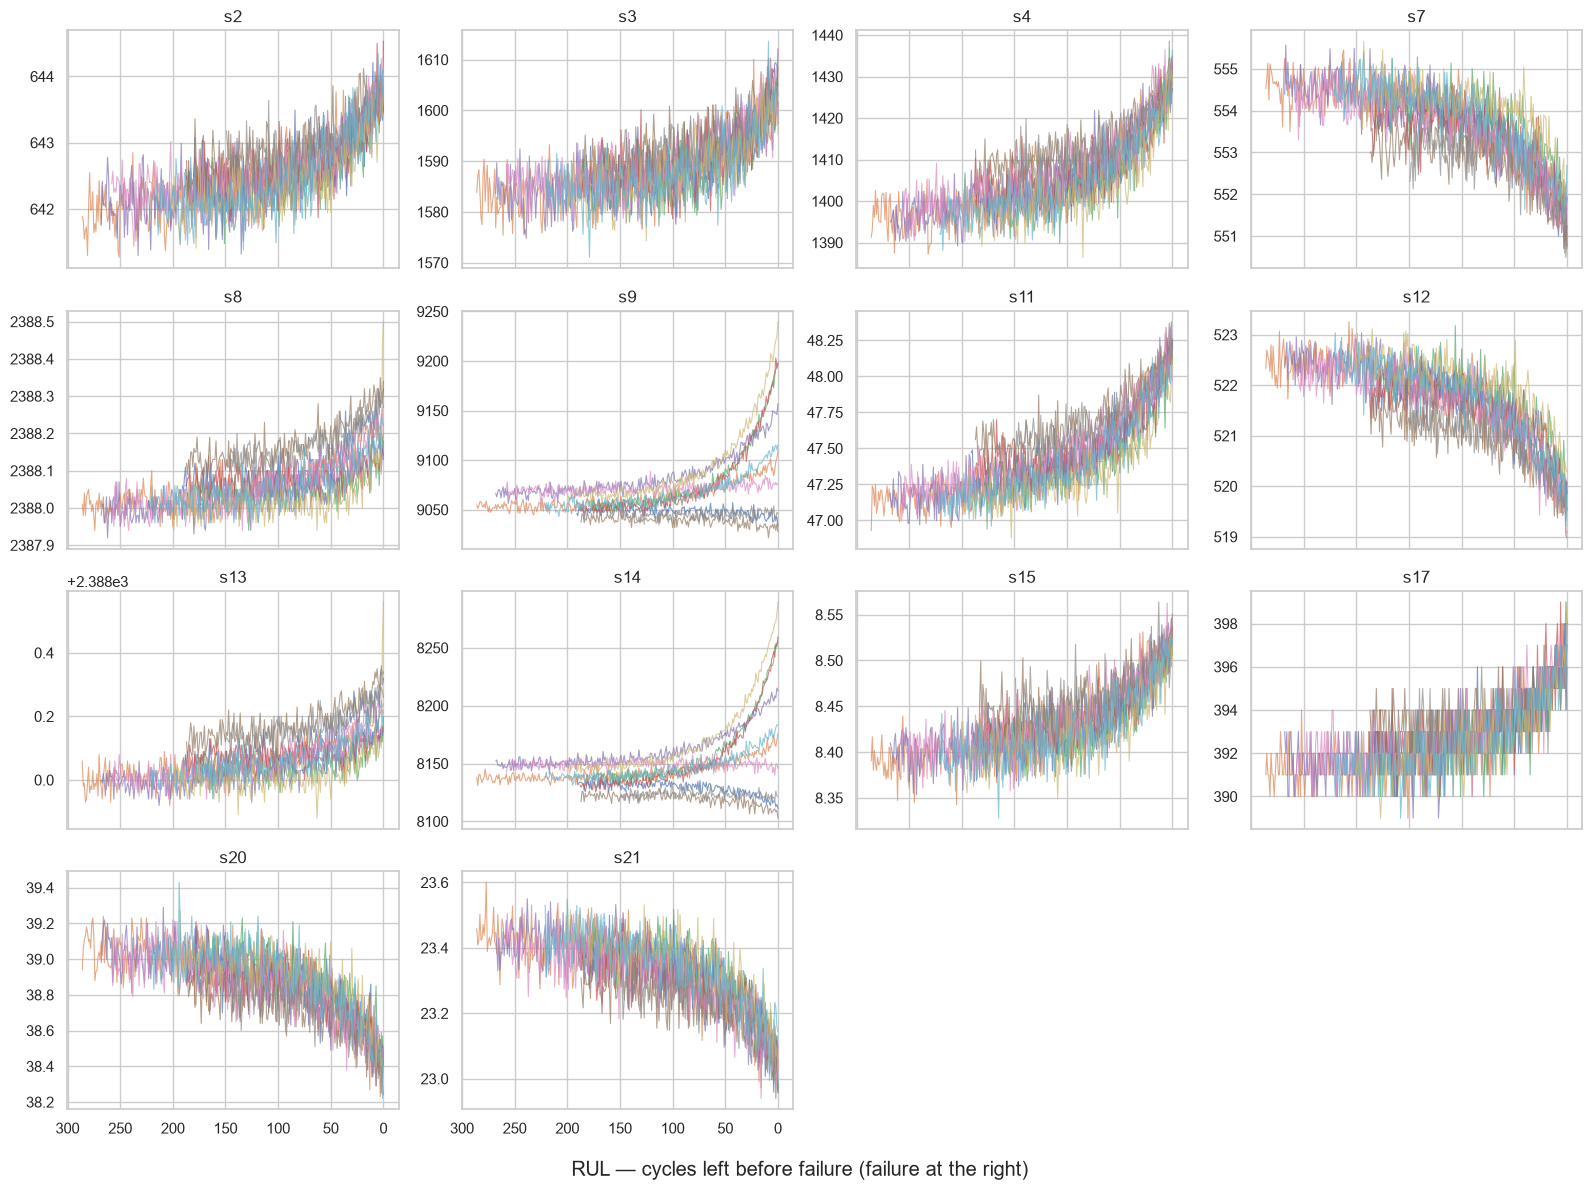

In [5]:
sample_units = train["unit"].unique()[:10]   # first 10 engines, for readability
n = len(useful_sensors)
ncols = 4
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3 * nrows), sharex=True)
for ax, s in zip(axes.flat, useful_sensors):
    for u in sample_units:
        d = train[train["unit"] == u]
        ax.plot(d["RUL"], d[s], linewidth=0.8, alpha=0.7)
    ax.set_title(s)
axes.flat[0].invert_xaxis()      # x-axis is shared, so this flips all plots: failure (RUL = 0) at the right
for ax in list(axes.flat)[n:]:
    ax.set_visible(False)
fig.supxlabel("RUL — cycles left before failure (failure at the right)")
plt.tight_layout()
plt.show()

**Takeaway:** most useful sensors change slowly while the engine is healthy and then **drift faster in the last ~50–100 cycles** before failure.
Some sensors go **up** with wear (e.g. s2, s3, s4, s11 — temperatures and pressure), others go **down** (s7, s12, s20, s21).
The readings are also **noisy** cycle-to-cycle — a single reading is unreliable, but the **trend** is clear.
→ This motivates the **rolling-average features** in Notebook 3.

**Exception — s9 and s14 (core speed):** they rise sharply for some engines and stay flat or even fall for others. Their behaviour depends on the individual engine, so they are weaker predictors (we will see this in the correlations too).

## 3. Healthy vs. near-failure: sensor distributions

We compare each sensor's values in the **healthy** part of life (RUL > 30) vs. the **last 30 cycles** (RUL ≤ 30).
If the two distributions are separated, the sensor is useful for classification.

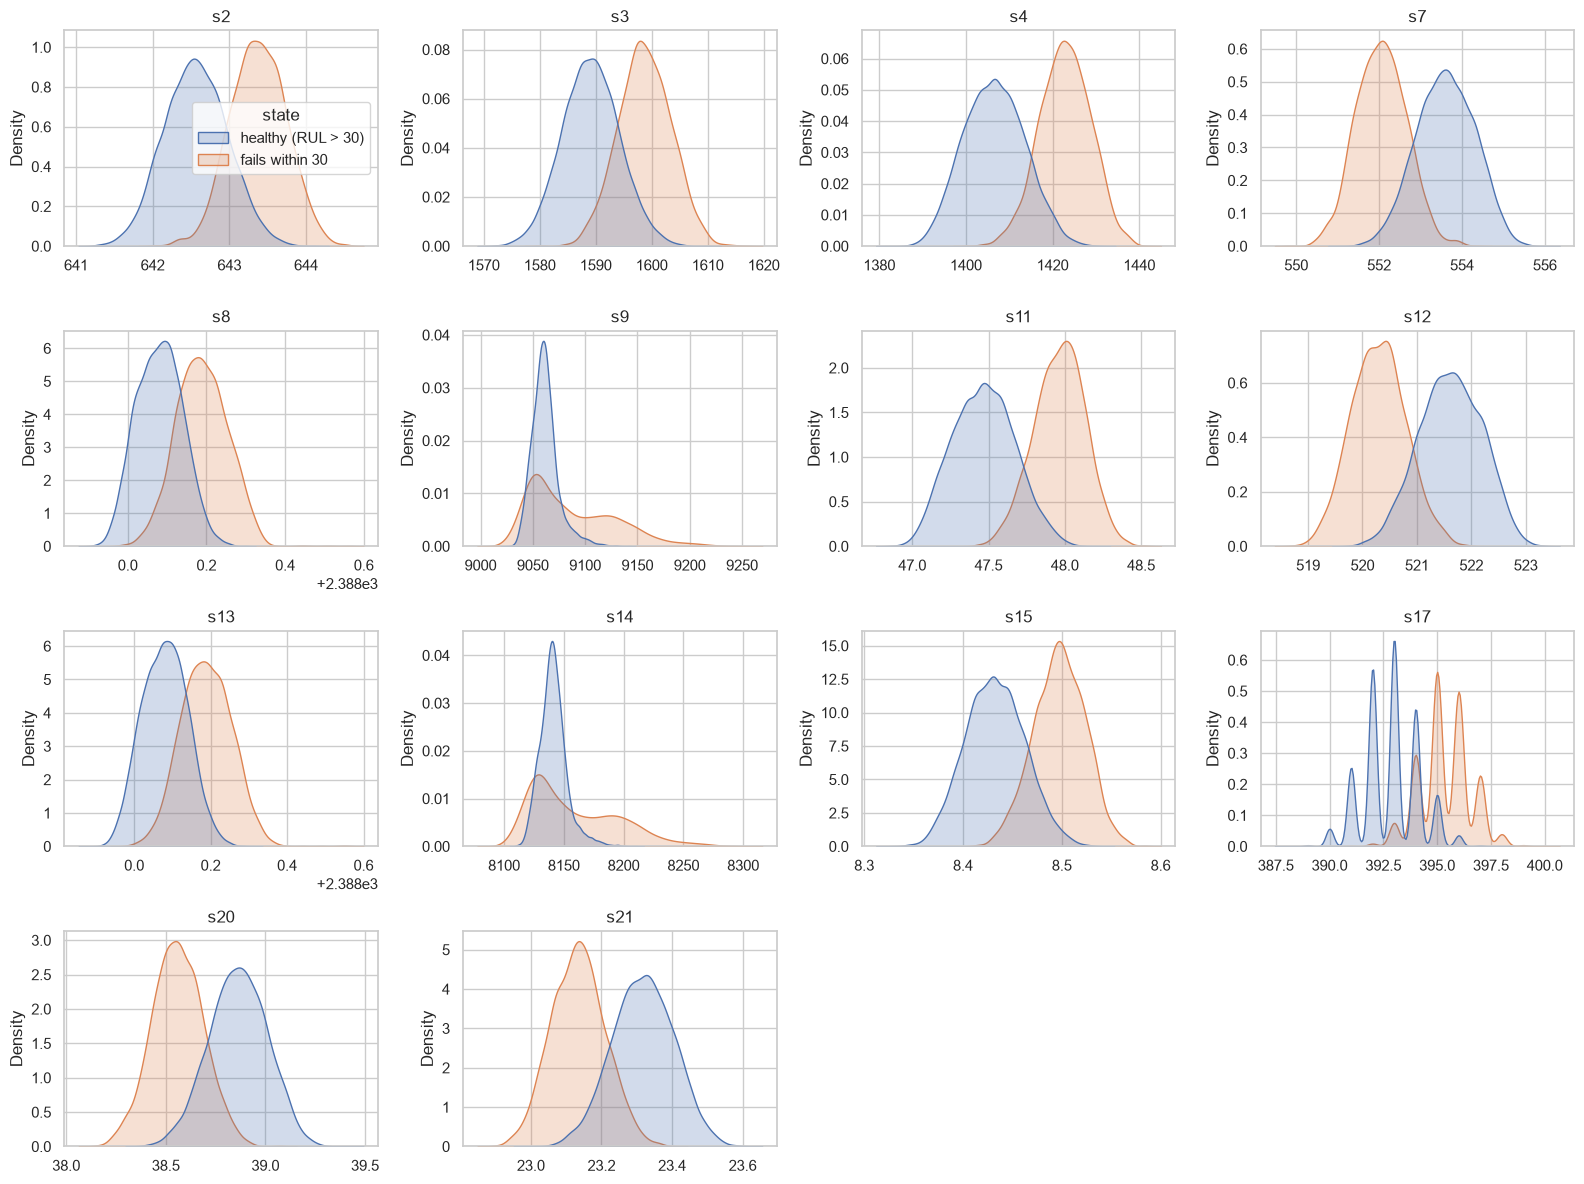

In [6]:
train["label"] = (train["RUL"] <= 30).astype(int)
plot_df = train.assign(state=train["label"].map({0: "healthy (RUL > 30)", 1: "fails within 30"}))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3 * nrows))
for i, (ax, s) in enumerate(zip(axes.flat, useful_sensors)):
    sns.kdeplot(data=plot_df, x=s, hue="state", common_norm=False, fill=True, ax=ax, legend=(i == 0))
    ax.set_title(s)
    ax.set_xlabel("")
for ax in list(axes.flat)[n:]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

**Takeaway:** for most useful sensors the two distributions are **shifted apart** — near-failure engines read hotter / higher-pressure (or lower, for some sensors).
They still **overlap**, so no single sensor is enough on its own → we need a model that combines them.

## 4. Correlations

**Correlation** (Pearson, from −1 to +1) measures how strongly two columns move together in a straight-line way.
- With **RUL**: which sensors carry information about remaining life?
- Between **sensors**: which sensors are redundant (tell the same story)?

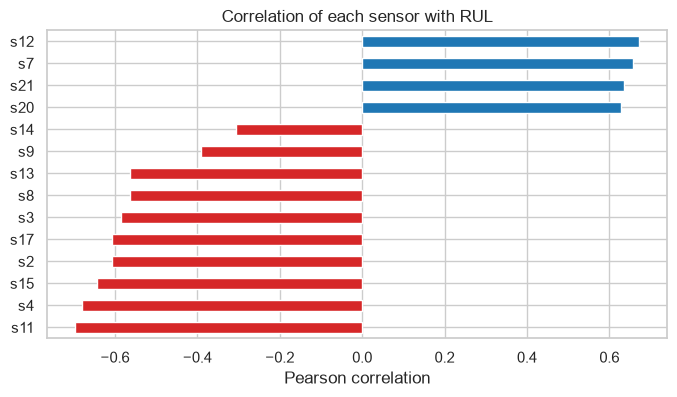

s11   -0.70
s4    -0.68
s15   -0.64
s2    -0.61
s17   -0.61
s3    -0.58
s8    -0.56
s13   -0.56
s9    -0.39
s14   -0.31
s20    0.63
s21    0.64
s7     0.66
s12    0.67
dtype: float64

In [7]:
corr_with_rul = train[useful_sensors].corrwith(train["RUL"]).sort_values()
plt.figure(figsize=(8, 4))
corr_with_rul.plot(kind="barh", color=["tab:red" if v < 0 else "tab:blue" for v in corr_with_rul])
plt.title("Correlation of each sensor with RUL")
plt.xlabel("Pearson correlation")
plt.show()
corr_with_rul.round(2)

**Takeaway:** negative correlation = the sensor **rises** as remaining life falls (wear makes it go up); positive = it **falls** with wear.
The strongest sensors (|r| ≈ 0.6–0.7) are s11, s4, s12, s7, s15, s21, s20. **s9 and s14 are the weakest** (|r| ≈ 0.3–0.4), matching their engine-dependent behaviour in the trend plot.

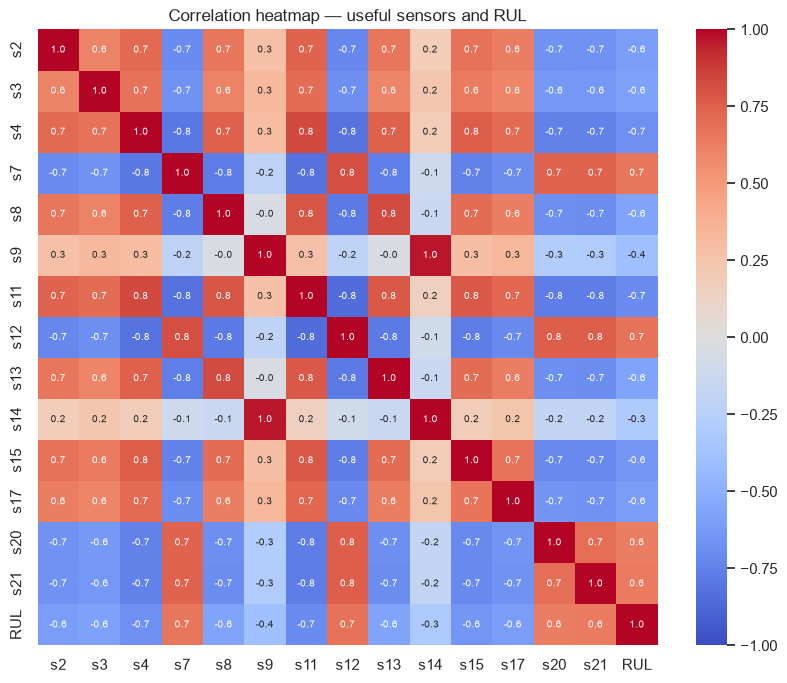

In [8]:
plt.figure(figsize=(10, 8))
sns.heatmap(train[useful_sensors + ["RUL"]].corr(), annot=True, fmt=".1f", cmap="coolwarm",
            vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Correlation heatmap — useful sensors and RUL")
plt.show()

**Takeaway:** many sensors are **strongly correlated with each other** (they all respond to the same compressor wear).
This redundancy (*multicollinearity*) can make plain logistic-regression weights unstable → one reason we use **regularization** (Notebook 4).

## 5. Class balance of the yes/no label

Label = 1 if the engine will fail within the next **30 cycles**, else 0.

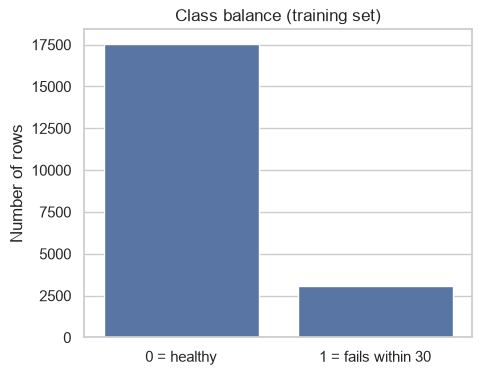

label
0    17531
1     3100
Name: count, dtype: int64
Positive share: 15.0%


In [9]:
counts = train["label"].value_counts().sort_index()
plt.figure(figsize=(5, 4))
sns.barplot(x=["0 = healthy", "1 = fails within 30"], y=counts.values)
plt.title("Class balance (training set)")
plt.ylabel("Number of rows")
plt.show()
print(counts)
print(f"Positive share: {train['label'].mean():.1%}")

**Takeaway:** the data is **imbalanced** (≈1 positive for every 5–6 negatives).
A useless model that always says "healthy" would already get ~85% accuracy → **accuracy is misleading**; we will use **recall, precision, F1 and ROC-AUC**,
and try `class_weight="balanced"` so the model pays more attention to the rare class.

## 6. Summary of EDA findings → decisions

| Finding | Decision |
|---|---|
| Settings and some sensors are constant | Drop them |
| Sensors drift as failure nears, but are noisy | Add **rolling mean / rolling std** features (Notebook 3) |
| No single sensor separates the classes | Use a model that combines many sensors |
| Sensors are strongly inter-correlated | Use **regularization** (L1/L2) |
| Label is imbalanced (~15% positive) | Use recall / precision / F1 / ROC-AUC; try class weights |
| Readings from one engine are related over time | Split data **by engine**, never by random row (Notebook 3) |

## Likely viva questions
- *Why did you drop those columns?* → Standard deviation ≈ 0: they don't change, so they can't help predict anything.
- *Why plot against RUL and not cycle?* → Engines have different lifetimes; aligning them at failure makes the degradation pattern comparable.
- *What does a correlation of −0.7 with RUL mean?* → Strong tendency: as remaining life goes down, that sensor goes up.
- *Why is accuracy misleading here?* → Imbalance: always predicting "healthy" gives ~85% accuracy but catches zero failures.

**Next → Notebook 3: Feature derivation and labelling.**